<a href="https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X6d_quaternions_perseguicao.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir no Colab"/></a>

# Domínio VI (d): para onde Pepé está olhando

## A orientação da cabeça de Pepé por um celular preso ao capacete: quatro filtros de atitude e o erro no corpo e no mundo

**Série:** [raiz](X0_raiz.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X0_raiz.ipynb)) · **Domínio:** [nó 6](X6_quaternions.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X6_quaternions.ipynb)) · **Anterior:** [X6c_quaternions_edo.ipynb](X6c_quaternions_edo.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X6c_quaternions_edo.ipynb))

**A história.** Pepé Le Gambá prendeu o celular no capacete. Ele quer saber, a cada instante, para onde está olhando: se o nariz aponta para Penélope, se a cabeça está inclinada. O celular tem três sensores, que são os mesmos de qualquer drone, satélite pequeno ou óculos de realidade virtual:
- um **giroscópio** (50 Hz), que mede a velocidade angular no referencial do celular, com ruído e com um **viés** desconhecido (em celulares, da ordem de 1 °/s, e que muda com a temperatura);
- um **acelerômetro**, que, com a cabeça parada ou andando devagar, mede a direção "para cima" (a reação à gravidade) no referencial do celular;
- um **magnetômetro**, que mede a direção do campo magnético da Terra (aponta para o norte magnético, inclinado para baixo; aqui, 40°).

O giroscópio integrado dá a orientação com detalhe, mas deriva (o viés acumula um erro que cresce sem parar). O acelerômetro e o magnetômetro não derivam, mas são ruidosos e, sozinhos, só dão a orientação quando a cabeça está parada. Os dois tipos de informação se completam: é o problema clássico de **estimação de atitude**, a base do quadrirrotor do [notebook 6 da série Kalman](../../kalman/notebooks/kalman_quadrotor_quaternions.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/kalman/notebooks/kalman_quadrotor_quaternions.ipynb)).

**O que é medido.** Duas direções conhecidas **no mundo**, $\mathbf g=(0,0,1)$ e $\mathbf m$, vistas **no corpo**: $\mathbf a=R(q)^\top\mathbf g+\text{ruído}$, $\mathbf m_{\text{med}}=R(q)^\top\mathbf m+\text{ruído}$. É o problema de Wahba do notebook VI(b), agora recursivo e com o giroscópio no meio.

**Os quatro filtros**, todos com o mesmo estado: orientação e viés do giroscópio.
1. **EKF aditivo:** $q$ como um vetor de $\mathbb R^4$, mais o viés: 7 estados para 6 graus de liberdade. Depois de cada atualização, $q$ é normalizado à força. Jacobianos por diferenças finitas.
2. **MEKF** (Markley, o filtro "multiplicativo", padrão em satélites): o estado de erro é uma pequena rotação **no corpo**, $q=\hat q\,\mathrm{Exp}(\delta\boldsymbol\theta)$, com 3 componentes. É o ESKF do [notebook 5 da série Kalman](../../kalman/notebooks/kalman_notas_im_kf_ekf_eskf_iekf_ieskf.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/kalman/notebooks/kalman_notas_im_kf_ekf_eskf_iekf_ieskf.ipynb)).
3. **IEKF** (o filtro invariante): o erro é uma pequena rotação **no mundo**, $q=\mathrm{Exp}(\boldsymbol\xi)\,\hat q$. Como as medidas são direções fixas no mundo, este é o erro "natural" (o mesmo argumento de Barrau e Bonnabel que fez o erro no mundo ganhar com os faróis no notebook V(d)).
4. **Mahony** (filtro complementar não linear, 2008): sem covariância. Compara as direções medidas com as previstas, e o produto vetorial entre elas vira uma correção de velocidade angular (proporcional e integral, como um controlador PI). É o que roda em muitos drones baratos.

**Roteiro**
1. A simulação: a cabeça de Pepé, o celular e os sensores
2. Os quatro filtros
3. Um ensaio
4. Monte Carlo, partindo de uma orientação razoável
5. Monte Carlo, ligando o celular sem saber o rumo
6. Exercícios

In [1]:
# Ferramentas comuns da série (repetidas em todos os notebooks, para que cada um rode sozinho no Colab)
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=6, suppress=True)
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3, "figure.dpi": 100,
                     "axes.spines.top": False, "axes.spines.right": False})

def confere(nome, obtido, esperado, tol=1e-9, relativo=False):
    """Compara duas quantidades. Imprime OK ou interrompe o notebook com uma mensagem clara."""
    a, b = np.asarray(obtido), np.asarray(esperado)
    tipo = complex if (np.iscomplexobj(a) or np.iscomplexobj(b)) else float      # aceita complexos (domínio IV)
    a, b = a.astype(tipo), b.astype(tipo)
    escala = max(np.max(np.abs(b)), 1e-300) if relativo else 1.0
    erro = float(np.max(np.abs(a - b)) / escala)
    ok = erro <= tol
    print(f"{'OK ' if ok else 'FALHOU'}  {nome}:  diferença {'relativa ' if relativo else ''}máxima = {erro:.2e}")
    assert ok, f"conferência falhou: {nome}"

def sinc(x):
    """sen(x)/x, sem perder dígitos perto de 0 (np.sinc usa sen(πx)/(πx))."""
    return np.sinc(np.asarray(x, float) / np.pi)

def qmul(a, b):
    """Produto de Hamilton de quaternions guardados como arrays (w, x, y, z); aceita pilhas (..., 4)."""
    a, b = np.asarray(a), np.asarray(b)
    w1, x1, y1, z1 = np.moveaxis(a, -1, 0); w2, x2, y2, z2 = np.moveaxis(b, -1, 0)
    return np.stack([w1 * w2 - x1 * x2 - y1 * y2 - z1 * z2,
                     w1 * x2 + x1 * w2 + y1 * z2 - z1 * y2,
                     w1 * y2 - x1 * z2 + y1 * w2 + z1 * x2,
                     w1 * z2 + x1 * y2 - y1 * x2 + z1 * w2], axis=-1)

def qconj(q):
    q = np.asarray(q); return q * np.array([1, -1, -1, -1])

def qnorm(q):
    q = np.asarray(q, float); return q / np.linalg.norm(q, axis=-1, keepdims=True)

def qrot(q, v):
    """O vetor v (3,) levado pela rotação q: a parte vetorial de q (0, v) q*."""
    return qmul(qmul(q, np.concatenate([[0.0], v])), qconj(q))[1:]

def qmat(q):
    """A matriz de rotação R(q), com R v = q v q* (q unitário)."""
    w, x, y, z = q
    return np.array([[1 - 2 * (y * y + z * z), 2 * (x * y - w * z), 2 * (x * z + w * y)],
                     [2 * (x * y + w * z), 1 - 2 * (x * x + z * z), 2 * (y * z - w * x)],
                     [2 * (x * z - w * y), 2 * (y * z + w * x), 1 - 2 * (x * x + y * y)]])

def mat_q(R):
    """De uma matriz de rotação para um quaternion (método de Shepperd: usa o maior pivô, sem perder dígitos)."""
    t = np.trace(R); d = np.diag(R)
    k = np.argmax([t, *d])
    if k == 0:
        w = np.sqrt(1 + t) / 2; q = [w, (R[2, 1] - R[1, 2]) / (4 * w), (R[0, 2] - R[2, 0]) / (4 * w), (R[1, 0] - R[0, 1]) / (4 * w)]
    elif k == 1:
        x = np.sqrt(1 + 2 * d[0] - t) / 2; q = [(R[2, 1] - R[1, 2]) / (4 * x), x, (R[0, 1] + R[1, 0]) / (4 * x), (R[0, 2] + R[2, 0]) / (4 * x)]
    elif k == 2:
        y = np.sqrt(1 + 2 * d[1] - t) / 2; q = [(R[0, 2] - R[2, 0]) / (4 * y), (R[0, 1] + R[1, 0]) / (4 * y), y, (R[1, 2] + R[2, 1]) / (4 * y)]
    else:
        z = np.sqrt(1 + 2 * d[2] - t) / 2; q = [(R[1, 0] - R[0, 1]) / (4 * z), (R[0, 2] + R[2, 0]) / (4 * z), (R[1, 2] + R[2, 1]) / (4 * z), z]
    q = np.array(q); return q if q[0] >= 0 else -q

def qexp(phi):
    """Exp do vetor de rotação φ = θ n: (cos(θ/2), sen(θ/2) n), com o sinc estável perto de θ = 0."""
    phi = np.asarray(phi, float); th = np.linalg.norm(phi)
    return np.concatenate([[np.cos(th / 2)], 0.5 * sinc(th / 2) * phi])

def qlog(q):
    """Log: o vetor de rotação φ de q (escolhendo o representante com w ≥ 0, isto é, |θ| ≤ π)."""
    q = np.asarray(q, float)
    if q[0] < 0: q = -q
    s = np.linalg.norm(q[1:]); th = 2 * np.arctan2(s, q[0])     # atan2: estável para ângulos pequenos e grandes
    return 2 * q[1:] / sinc(th / 2)

def slerp(q0, q1, s):
    """Interpolação esférica: q0 Exp(s Log(q0* q1)), pelo arco mais curto."""
    return qmul(q0, qexp(s * qlog(qmul(qconj(q0), q1))))

def chapeu(v):
    """A matriz antissimétrica [v]×, com [v]× u = v × u."""
    return np.array([[0, -v[2], v[1]], [v[2], 0, -v[0]], [-v[1], v[0], 0]])

H = 0.02                       # período do giroscópio: 50 Hz
SUB = 10                       # subpassos da simulação da verdade
SIG_G = 0.005                  # ruído do giroscópio por amostra (rad/s)
SIG_BW = 1e-4                  # passeio aleatório do viés, por amostra (rad/s)
SIG_A, SIG_M = 0.03, 0.05      # ruído de direção do acelerômetro e do magnetômetro (rad)
DT_MED = 0.1                   # acelerômetro e magnetômetro usados a 10 Hz
G_W = np.array([0, 0, 1.0])    # "para cima" no mundo
INC = np.radians(40)
M_W = np.array([np.cos(INC), 0, -np.sin(INC)])    # o campo: para o norte (x), inclinado 40° para baixo

---

## 1. A simulação

A cabeça de Pepé olha em volta: a velocidade angular no corpo é uma soma de senóides lentas (até 1 rad/s na guinada, menos na arfagem e na rolagem), mais uma **virada rápida** no meio do ensaio (quando ele ouve Penélope: uns 45° em 0,3 s). A orientação verdadeira é integrada com 10 subpassos por amostra do giroscópio. O giroscópio entrega a média da velocidade em cada intervalo, mais o viés (sorteado com desvio de 0,02 rad/s ≈ 1,1 °/s por eixo, e com um passeio aleatório lento), mais ruído. As direções medidas são as verdadeiras perturbadas por pequenas rotações aleatórias.

In [2]:
def cabeca(rng, T):
    amp = np.array([0.3, 0.5, 1.0]); fr = rng.uniform(0.1, 0.4, (3, 3)); fa = rng.uniform(0, 2 * np.pi, (3, 3))
    def w(t):
        base = np.array([sum(amp[i] / 3 * np.sin(2 * np.pi * fr[i, j] * t + fa[i, j]) for j in range(3)) for i in range(3)])
        return base + np.array([0, 0, 3.0 * np.exp(-((t - T / 2) / 0.15)**2)])     # a virada rápida, em torno do eixo vertical da cabeça
    return w

def simula(rng, T=30.0):
    w = cabeca(rng, T)
    n = int(round(T / H)); q = qnorm(rng.normal(size=4)); b = rng.normal(0, 0.02, 3)
    Qv, WM, Bv = [q], [], [b]
    for k in range(n):
        inc = np.zeros(3); h = H / SUB
        for s in range(SUB):
            t = k * H + (s + 0.5) * h
            q = qmul(q, qexp(h * w(t))); inc += h * w(t)
        b = b + SIG_BW * rng.normal(size=3)
        WM.append(inc / H + b + SIG_G * rng.normal(size=3)); Qv.append(q); Bv.append(b)
    Qv = np.array(Qv); passo_med = int(round(DT_MED / H)); med = {}
    for k in range(passo_med, n + 1, passo_med):
        R = qmat(Qv[k])
        med[k] = (qrot(qexp(SIG_A * rng.normal(size=3)), R.T @ G_W), qrot(qexp(SIG_M * rng.normal(size=3)), R.T @ M_W))
    return Qv, np.array(WM), np.array(Bv), med

rng = np.random.default_rng(64)
Qv, WM, Bv, med = simula(rng)
print(f"{len(WM)} amostras do giroscópio, {len(med)} pares (acelerômetro, magnetômetro); "
      f"a virada soma {np.degrees(3.0 * 0.15 * np.sqrt(np.pi)):.0f}° ao giro da cabeça em menos de meio segundo")
print(f"viés verdadeiro do giroscópio: {np.degrees(Bv[0])} °/s")
so_giro = [Qv[0]]
for wm in WM: so_giro.append(qmul(so_giro[-1], qexp(wm * H)))
print(f"só integrando o giroscópio (partindo da orientação certa), o erro depois de 30 s é {np.degrees(np.linalg.norm(qlog(qmul(qconj(so_giro[-1]), Qv[-1])))):.0f}°")

1500 amostras do giroscópio, 300 pares (acelerômetro, magnetômetro); a virada soma 46° ao giro da cabeça em menos de meio segundo
viés verdadeiro do giroscópio: [ 1.01739   0.741385 -0.201714] °/s
só integrando o giroscópio (partindo da orientação certa), o erro depois de 30 s é 34°


---

## 2. Os quatro filtros

As contas do MEKF e do IEKF são as do notebook V(d), com $\mathfrak{so}(3)$ no lugar de $\mathfrak{se}(2)$. Com $\hat{\boldsymbol\omega}=\boldsymbol\omega_{\text{med}}-\hat{\mathbf b}$, a predição da orientação é a mesma nos dois, $\hat q\leftarrow\hat q\,\mathrm{Exp}(\hat{\boldsymbol\omega}h)$; o que muda é como o erro evolui e como a medida depende dele:

| | erro | $F$ (erro de orientação; erro de viés) | $H$ de uma direção $\mathbf r$ do mundo | correção |
|---|---|---|---|---|
| MEKF | $q=\hat q\,\mathrm{Exp}(\delta\boldsymbol\theta)$ | $\mathrm{Exp}(-\hat{\boldsymbol\omega}h)$;  $-h\,I$ | $[\hat R^\top\mathbf r]_\times$ | $\hat q\leftarrow\hat q\,\mathrm{Exp}(\delta\boldsymbol\theta)$ |
| IEKF | $q=\mathrm{Exp}(\boldsymbol\xi)\,\hat q$ | $I$;  $-h\,\hat R$ | $\hat R^\top[\mathbf r]_\times$ | $\hat q\leftarrow\mathrm{Exp}(\boldsymbol\xi)\,\hat q$ |

Repare na coluna do meio: no IEKF, sem viés, o erro de orientação **não muda** na predição ($F=I$), qualquer que seja o movimento. O erro no mundo é invariante pela rotação do corpo, porque as medidas também estão presas ao mundo. A covariância inicial é dada no corpo ($\delta\boldsymbol\theta$) e levada ao mundo por $\boldsymbol\xi=\hat R\,\delta\boldsymbol\theta$.

In [3]:
RM = np.diag([SIG_A**2] * 3 + [SIG_M**2] * 3)

class MEKF:
    nome = "MEKF (erro no corpo)"
    def __init__(s, q0, P0): s.q = q0.copy(); s.b = np.zeros(3); s.P = P0.copy()
    def prediz(s, wm):
        wh = wm - s.b
        F = np.eye(6); F[:3, :3] = qmat(qexp(-wh * H)); F[:3, 3:] = -H * np.eye(3)
        s.q = qmul(s.q, qexp(wh * H)); s.P = F @ s.P @ F.T + np.diag([SIG_G**2 * H**2] * 3 + [SIG_BW**2] * 3)
    def jacobiano(s, R):
        Hm = np.zeros((6, 6)); Hm[:3, :3] = chapeu(R.T @ G_W); Hm[3:, :3] = chapeu(R.T @ M_W); return Hm
    def corrige(s, dth): s.q = qmul(s.q, qexp(dth))
    def atualiza(s, a, m):
        R = qmat(s.q); z = np.concatenate([a, m]); zh = np.concatenate([R.T @ G_W, R.T @ M_W])
        Hm = s.jacobiano(R); S = Hm @ s.P @ Hm.T + RM; K = s.P @ Hm.T @ np.linalg.inv(S); dx = K @ (z - zh)
        s.corrige(dx[:3]); s.b = s.b + dx[3:]; s.P = (np.eye(6) - K @ Hm) @ s.P
    def erro(s, q): return qlog(qmul(qconj(s.q), q))          # no corpo
    def Pth(s): return s.P[:3, :3]

class IEKF(MEKF):
    nome = "IEKF (erro no mundo)"
    def prediz(s, wm):
        wh = wm - s.b; R = qmat(s.q)
        F = np.eye(6); F[:3, 3:] = -H * R
        s.q = qmul(s.q, qexp(wh * H)); s.P = F @ s.P @ F.T + np.diag([SIG_G**2 * H**2] * 3 + [SIG_BW**2] * 3)   # R I Rᵀ = I
    def jacobiano(s, R):
        Hm = np.zeros((6, 6)); Hm[:3, :3] = R.T @ chapeu(G_W); Hm[3:, :3] = R.T @ chapeu(M_W); return Hm
    def corrige(s, xi): s.q = qmul(qexp(xi), s.q)
    def erro(s, q): return qlog(qmul(q, qconj(s.q)))          # no mundo

class EKFAditivo:
    nome = "EKF aditivo (4 componentes)"
    def __init__(s, q0, P0):
        s.x = np.concatenate([q0, np.zeros(3)])
        G = 0.5 * np.vstack([-q0[1:], q0[0] * np.eye(3) + chapeu(q0[1:])])      # δq ≈ ½ q ⊗ (0, δθ)
        s.P = np.zeros((7, 7)); s.P[:4, :4] = G @ P0[:3, :3] @ G.T; s.P[4:, 4:] = P0[3:, 3:]
    @staticmethod
    def f(x, wm): return np.concatenate([qmul(x[:4], qexp((wm - x[4:]) * H)), x[4:]])
    @staticmethod
    def h(x):
        R = qmat(qnorm(x[:4])); return np.concatenate([R.T @ G_W, R.T @ M_W])
    @staticmethod
    def jac(fun, x, e=1e-7):
        f0 = fun(x); J = np.zeros((len(f0), len(x)))
        for i in range(len(x)):
            d = np.zeros(len(x)); d[i] = e; J[:, i] = (fun(x + d) - fun(x - d)) / (2 * e)
        return J
    def prediz(s, wm):
        F = s.jac(lambda x: s.f(x, wm), s.x)
        L = np.zeros((7, 6)); L[:4, :3] = F[:4, 4:]; L[4:, 3:] = np.eye(3)     # o ruído do giroscópio entra como o viés
        s.x = s.f(s.x, wm); s.P = F @ s.P @ F.T + L @ np.diag([SIG_G**2] * 3 + [SIG_BW**2] * 3) @ L.T
    def atualiza(s, a, m):
        Hm = s.jac(s.h, s.x); S = Hm @ s.P @ Hm.T + RM; K = s.P @ Hm.T @ np.linalg.inv(S)
        s.x = s.x + K @ (np.concatenate([a, m]) - s.h(s.x)); s.P = (np.eye(7) - K @ Hm) @ s.P
        s.x[:4] = qnorm(s.x[:4])                                     # a normalização à força
    @property
    def q(s): return s.x[:4]
    @property
    def b(s): return s.x[4:]
    def erro(s, q): return qlog(qmul(qconj(s.q), q))
    def Pth(s):
        q = s.q; G = 2 * np.hstack([-q[1:, None], q[0] * np.eye(3) - chapeu(q[1:])])   # δθ ≈ 2 vet(q̂* δq)
        return G @ s.P[:4, :4] @ G.T

class Mahony:
    nome = "Mahony (complementar)"
    KP, KI = 1.0, 0.05
    def __init__(s, q0, P0=None): s.q = q0.copy(); s.b = np.zeros(3); s.e = np.zeros(3)
    def prediz(s, wm):
        s.q = qmul(s.q, qexp((wm - s.b + s.KP * s.e) * H)); s.b = s.b - s.KI * s.e * H
    def atualiza(s, a, m):
        R = qmat(s.q); s.e = np.cross(a, R.T @ G_W) + np.cross(m, R.T @ M_W)
    def erro(s, q): return qlog(qmul(qconj(s.q), q))

FILTROS = [EKFAditivo, MEKF, IEKF, Mahony]

def roda(Cls, Qv, WM, med, q0, P0):
    if Cls is IEKF:
        P0 = P0.copy(); R0 = qmat(q0); P0[:3, :3] = R0 @ P0[:3, :3] @ R0.T      # do corpo para o mundo
    f = Cls(q0, P0); E, NE, B = [], [], []
    for k in range(len(WM)):
        f.prediz(WM[k])
        if (k + 1) in med: f.atualiza(*med[k + 1])
        e = f.erro(Qv[k + 1]); E.append(np.linalg.norm(e)); B.append(f.b.copy())
        if hasattr(f, "Pth"): NE.append(e @ np.linalg.solve(f.Pth(), e))
    return np.array(E), (np.array(NE) if NE else None), np.array(B)

# conferências dos jacobianos analíticos por diferenças finitas
q_ = qnorm(rng.normal(size=4)); R_ = qmat(q_); e_ = 1e-7
for nome, pert, Hf in [("MEKF", lambda d: qmul(q_, qexp(d)), MEKF.jacobiano(None, R_)), ("IEKF", lambda d: qmul(qexp(d), q_), IEKF.jacobiano(None, R_))]:
    J = np.column_stack([(np.concatenate([qmat(pert(e_ * u)).T @ G_W, qmat(pert(e_ * u)).T @ M_W]) -
                          np.concatenate([qmat(pert(-e_ * u)).T @ G_W, qmat(pert(-e_ * u)).T @ M_W])) / (2 * e_) for u in np.eye(3)])
    confere(f"jacobiano da medida do {nome} = diferenças finitas", Hf[:, :3], J, tol=1e-8)

OK   jacobiano da medida do MEKF = diferenças finitas:  diferença máxima = 2.22e-09
OK   jacobiano da medida do IEKF = diferenças finitas:  diferença máxima = 2.22e-09


---

## 3. Um ensaio

Os filtros partem da orientação verdadeira perturbada por um erro sorteado de 5° em inclinação e 10° em rumo (a covariância inicial diz exatamente isso), com viés estimado zero.

EKF aditivo (4 componentes) : erro RMS depois de 10 s 0.80°;  erro do viés no fim 0.150 °/s
MEKF (erro no corpo)        : erro RMS depois de 10 s 0.80°;  erro do viés no fim 0.149 °/s
IEKF (erro no mundo)        : erro RMS depois de 10 s 0.80°;  erro do viés no fim 0.150 °/s
Mahony (complementar)       : erro RMS depois de 10 s 1.18°;  erro do viés no fim 0.328 °/s


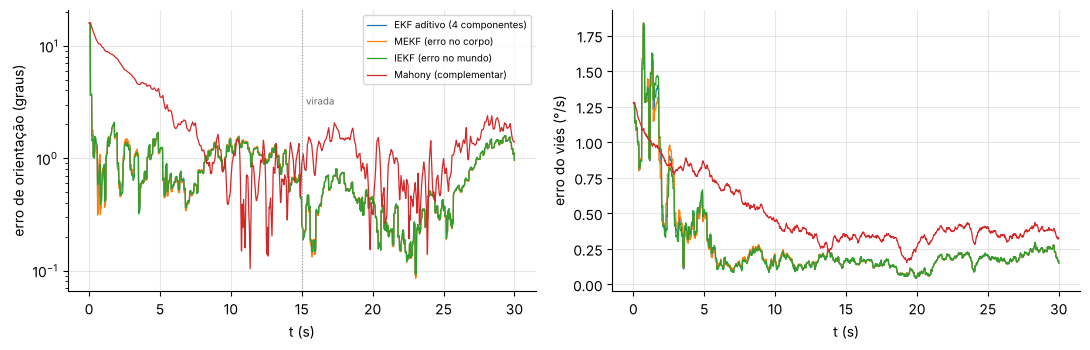

In [4]:
SIG0_CALMO = np.radians([5.0, 5.0, 10.0])
P0 = np.diag([*SIG0_CALMO**2, *[0.03**2] * 3])
q0 = qmul(Qv[0], qexp(-SIG0_CALMO * rng.normal(size=3)))          # verdade = q0 ⊞ δθ
ts = np.arange(1, len(WM) + 1) * H
ensaio = {Cls.nome: roda(Cls, Qv, WM, med, q0, P0) for Cls in FILTROS}
for nome, (E, NE, B) in ensaio.items():
    print(f"{nome:28s}: erro RMS depois de 10 s {np.degrees(np.sqrt(np.mean(E[ts > 10]**2))):.2f}°;  "
          f"erro do viés no fim {np.degrees(np.linalg.norm(B[-1] - Bv[-1])):.3f} °/s")

fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
for nome, (E, NE, B) in ensaio.items():
    axs[0].semilogy(ts, np.degrees(E), lw=0.9, label=nome)
    axs[1].plot(ts, np.degrees(np.linalg.norm(B - Bv[1:], axis=1)), lw=0.9, label=nome)
axs[0].axvline(15, color="0.6", ls=":", lw=0.8); axs[0].text(15.3, 3, "virada", fontsize=7, color="0.4")
axs[0].set_xlabel("t (s)"); axs[0].set_ylabel("erro de orientação (graus)"); axs[0].legend(fontsize=7)
axs[1].set_xlabel("t (s)"); axs[1].set_ylabel("erro do viés (°/s)")
plt.tight_layout(); plt.show()

---

## 4. Monte Carlo, partindo de uma orientação razoável

Vinte ensaios de 30 s, cada um com outra cabeça, outro viés e outros ruídos. Para os três filtros com covariância, o **NEES** (o erro ao quadrado ponderado pela covariância do próprio filtro, notebook IV(d)) deve ficar perto de 3, o número de componentes do erro de orientação.

In [5]:
def monte_carlo(sig0, n=20, rumo_desconhecido=False, semente=640):
    rng_ = np.random.default_rng(semente); res = {Cls.nome: [] for Cls in FILTROS}
    for _ in range(n):
        Qv_, WM_, Bv_, med_ = simula(rng_)
        dth = sig0 * rng_.normal(size=3)
        if rumo_desconhecido: dth[2] = rng_.choice([-1, 1]) * rng_.uniform(np.radians(110), np.radians(160))
        q0_ = qmul(Qv_[0], qexp(-dth))
        P0_ = np.diag([*sig0**2, *[0.03**2] * 3])
        for Cls in FILTROS:
            res[Cls.nome].append(roda(Cls, Qv_, WM_, med_, q0_, P0_)[:2])
    return res

def resume(res):
    n1 = int(1 / H); tab = {}
    print(f"{'filtro':28s} erro em 1 s   em 5 s    RMS depois de 10 s    NEES 0–2 s   NEES depois de 10 s")
    for nome, L in res.items():
        E = np.degrees(np.array([x[0] for x in L]))
        linha = [np.median(E[:, n1 - 1]), np.median(E[:, 5 * n1 - 1]), np.sqrt(np.mean(E[:, 10 * n1:]**2))]
        if L[0][1] is not None:
            NE = np.array([x[1] for x in L]); linha += [NE[:, :2 * n1].mean(), NE[:, 10 * n1:].mean()]
        tab[nome] = linha
        print(f"{nome:28s} {linha[0]:8.2f}°  {linha[1]:7.2f}°      {linha[2]:7.2f}°" + (f"          {linha[3]:8.2f}      {linha[4]:8.2f}" if len(linha) > 3 else "")
              + ("" if len(linha) > 3 else "          (sem covariância)"))
    return tab

mc_calmo = monte_carlo(SIG0_CALMO)
tab_calmo = resume(mc_calmo)
nees_fim = [tab_calmo[n_][4] for n_ in ["EKF aditivo (4 componentes)", "MEKF (erro no corpo)", "IEKF (erro no mundo)"]]
confere("os três filtros com covariância são consistentes depois de 10 s (NEES entre 2 e 4)", [2 < x < 4 for x in nees_fim], [True] * 3)
confere("e erram praticamente o mesmo (RMS a menos de 5% um do outro)",
        max(tab_calmo[n_][2] for n_ in tab_calmo if "Mahony" not in n_) / min(tab_calmo[n_][2] for n_ in tab_calmo if "Mahony" not in n_), 1, tol=0.05)

filtro                       erro em 1 s   em 5 s    RMS depois de 10 s    NEES 0–2 s   NEES depois de 10 s
EKF aditivo (4 componentes)      1.46°     0.99°         0.78°              2.41          2.75
MEKF (erro no corpo)             1.49°     1.00°         0.78°              2.42          2.75
IEKF (erro no mundo)             1.43°     0.99°         0.78°              2.41          2.76
Mahony (complementar)            3.78°     2.56°         2.09°          (sem covariância)
OK   os três filtros com covariância são consistentes depois de 10 s (NEES entre 2 e 4):  diferença máxima = 0.00e+00
OK   e erram praticamente o mesmo (RMS a menos de 5% um do outro):  diferença máxima = 1.36e-03


**Leitura.** Partindo de um erro de 5° a 10°, os três filtros com covariância são praticamente **o mesmo filtro**: erram 0,78° (RMS, depois de 10 s), com NEES de 2,75, um pouco abaixo de 3 (ligeiramente pessimistas), e estimam o viés do giroscópio com a mesma precisão. Com erros pequenos, todas as linearizações são boas, e a definição do erro (no corpo, no mundo ou nas componentes) não faz diferença. Até o EKF aditivo, com 7 estados para 6 graus de liberdade e a normalização à força, empata. O filtro de Mahony erra 2,1°, quase três vezes mais, e estima o viés mais devagar; em compensação, não multiplica nenhuma matriz, e é por isso que roda nos microcontroladores mais simples. Só o giroscópio, sem os outros sensores, teria errado 34° em 30 s.

---

## 5. Ligando o celular sem saber o rumo

Pepé liga o celular já com o capacete na cabeça, virado para uma direção qualquer. A inclinação sai logo do acelerômetro, mas o rumo inicial é um chute: o erro verdadeiro de rumo é sorteado entre 110° e 160° (para um lado ou para o outro), e os filtros recebem uma covariância inicial honesta, com desvio de 150° no rumo. Agora o erro inicial é grande, e a linearização dos três EKFs é posta à prova.

filtro                       erro em 1 s   em 5 s    RMS depois de 10 s    NEES 0–2 s   NEES depois de 10 s
EKF aditivo (4 componentes)     20.47°    18.14°         4.76°           1499.09         56.00
MEKF (erro no corpo)            23.62°    14.14°         5.52°           1438.20         76.08
IEKF (erro no mundo)             9.56°     7.11°         2.06°            686.09         14.06
Mahony (complementar)           81.35°    13.42°         7.58°          (sem covariância)
OK   com erro inicial grande, o IEKF converge mais rápido que os outros dois EKFs (mediana em 1 s):  diferença máxima = 0.00e+00
OK   e erra menos depois de 10 s:  diferença máxima = 0.00e+00
OK   mas nenhum dos três é consistente no começo (NEES 0–2 s acima de 100):  diferença máxima = 0.00e+00


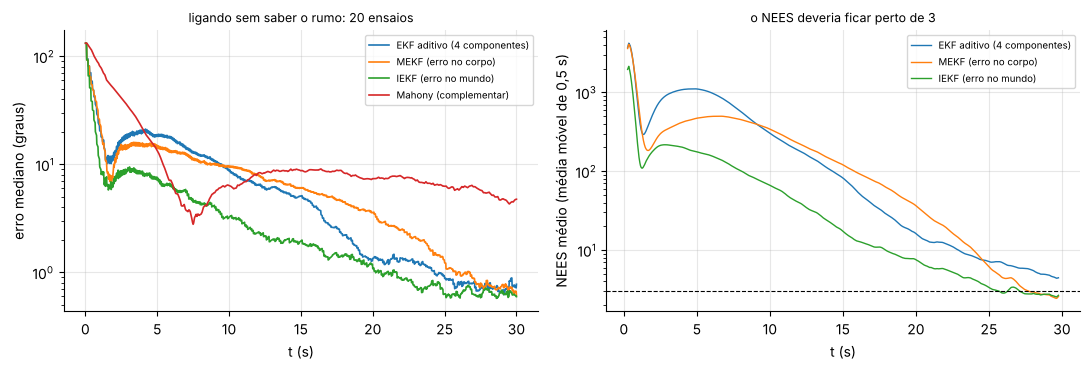

In [6]:
SIG0_RUMO = np.radians([5.0, 5.0, 150.0])
mc_rumo = monte_carlo(SIG0_RUMO, rumo_desconhecido=True, semente=641)
tab_rumo = resume(mc_rumo)
confere("com erro inicial grande, o IEKF converge mais rápido que os outros dois EKFs (mediana em 1 s)",
        tab_rumo["IEKF (erro no mundo)"][0] < min(tab_rumo["MEKF (erro no corpo)"][0], tab_rumo["EKF aditivo (4 componentes)"][0]), True)
confere("e erra menos depois de 10 s", tab_rumo["IEKF (erro no mundo)"][2] < min(tab_rumo["MEKF (erro no corpo)"][2], tab_rumo["EKF aditivo (4 componentes)"][2]), True)
confere("mas nenhum dos três é consistente no começo (NEES 0–2 s acima de 100)", [tab_rumo[n_][3] > 100 for n_ in tab_rumo if "Mahony" not in n_], [True] * 3)

fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
for nome, L in mc_rumo.items():
    E = np.degrees(np.array([x[0] for x in L]))
    axs[0].semilogy(ts, np.median(E, axis=0), lw=1.2, label=nome)
    if L[0][1] is not None:
        NE = np.array([x[1] for x in L]).mean(0)
        axs[1].semilogy(ts[12:-12], np.convolve(NE, np.ones(25) / 25, mode="valid"), lw=1, label=nome)
axs[0].set_xlabel("t (s)"); axs[0].set_ylabel("erro mediano (graus)"); axs[0].legend(fontsize=7)
axs[0].set_title("ligando sem saber o rumo: 20 ensaios", fontsize=9)
axs[1].axhline(3, color="k", ls="--", lw=0.8); axs[1].set_xlabel("t (s)"); axs[1].set_ylabel("NEES médio (média móvel de 0,5 s)")
axs[1].set_title("o NEES deveria ficar perto de 3", fontsize=9); axs[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

**Leitura.** Agora as diferenças aparecem. No primeiro segundo, o acelerômetro e o magnetômetro derrubam o erro de mais de 100° para a casa dos 10° a 25°, e o IEKF vai mais longe (mediana de 9,6°, contra 20° do EKF aditivo e 24° do MEKF). Depois de 10 s, o IEKF erra 2,1° (RMS), contra 4,8° e 5,5°. O filtro de Mahony, sem linearização nenhuma, sai de qualquer erro inicial, mas devagar (81° depois de 1 s) e termina pior.

O lado de baixo da história é a consistência. **Nenhum** dos três EKFs é consistente no começo: o NEES dos dois primeiros segundos fica entre 690 e 1500, em vez de 3. As primeiras atualizações são linearizadas em torno de um rumo muito errado, e encolhem a covariância como se a linearização valesse. Depois disso, o filtro confia demais em si mesmo, dá pouco peso às medidas novas, e a convergência se arrasta por mais de 20 s (a figura da esquerda). O IEKF sofre menos (o NEES dele é a metade e chega a 3 antes), mas não é imune: a garantia do erro no mundo vale para a predição sem viés; com o viés e com a atualização linearizada, a invariância é só aproximada. Foi a mesma lição do GPS desorientado no notebook V(d), com mais força: a melhor definição do erro ajuda, mas não substitui uma boa inicialização. Na prática, os sistemas começam calculando a orientação de uma vez com as primeiras medidas (o problema de Wahba do notebook VI(b)) e só então ligam o filtro (exercício 6).

---

## 6. Exercícios

1. **Pepé corre.** Correndo, a cabeça acelera (picos de 0,5 g), e o acelerômetro deixa de medir só a gravidade. Acrescente uma aceleração linear à simulação e veja os quatro filtros errarem a inclinação. Depois, proteja o MEKF: rejeite a medida do acelerômetro quando $\lvert\,\lvert\mathbf a\rvert-g\,\rvert$ for grande, ou quando o NIS (notebook II(d)) passar de um limiar.
2. **Uma cerca de metal.** Perto de ferro, o campo magnético se distorce. Gire $\mathbf m$ medido de 30° em torno da vertical durante 5 s. Os filtros erram só o rumo, ou a inclinação também? Por quê? (Pense no jacobiano da medida do magnetômetro: ele tem componentes de inclinação.) Uma saída comum é usar do magnetômetro só a componente horizontal.
3. **O ganho do Mahony.** Varie $k_P$ de 0,2 a 3 e meça o erro RMS e o tempo de convergência. Existe um ganho que empate com o MEKF nos dois cenários?
4. **Sem viés, o IEKF é exato.** Zere o viés na simulação e nos filtros. Mostre que, no IEKF, a covariância depois da predição não depende de $\hat q$ nem de $\hat{\boldsymbol\omega}$. O que isso implica para o NEES no cenário do rumo desconhecido?
5. **De volta a Penélope.** Penélope está num ponto conhecido do mundo. Usando a orientação estimada, calcule o ângulo entre o nariz de Pepé (o eixo $x$ do celular) e a direção de Penélope, com a sua incerteza (propague a covariância do erro de orientação). Quando Pepé pode ter 95% de certeza de que está olhando para ela, a menos de 5°?
6. **Inicializar pelo problema de Wahba.** No cenário do rumo desconhecido, calcule a orientação inicial com o método q de Davenport (notebook VI(b)) usando o primeiro par (acelerômetro, magnetômetro), com a covariância de Shuster, e só então ligue os filtros. O NEES dos primeiros segundos fica perto de 3? Qual filtro ganha agora?